<a href="https://colab.research.google.com/github/HiroshiATakano/GitHub/blob/master/6_%E6%B1%BA%E5%AE%9A%E5%88%86%E6%9E%90%EF%BC%BF%E6%A4%9C%E8%A8%BC%E7%94%A8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [12]:
import os

pth = os.getcwd()

try:
  os.chdir(pth + '/drive/My Drive/ThinkBayes')
except:
  pass

pth = os.getcwd()
pth

'/content/drive/My Drive/ThinkBayes'

In [13]:
!pip install japanize_matplotlib

In [14]:
import numpy as np
import scipy
import pandas as pd
import thinkbayes

import matplotlib.pyplot as plt
import japanize_matplotlib
import seaborn as sns

%matplotlib inline

In [15]:
df = pd.read_csv("showcases.2011.csv").T

df.columns = df.iloc[0]
df = df.iloc[1:].reset_index(drop=True)
df = df.loc[:, df.columns.notna()]
df = df.astype(float)
df1 = df.copy()

In [16]:
df = pd.read_csv("showcases.2012.csv").T

df.columns = df.iloc[0]
df = df.iloc[1:].reset_index(drop=True)
df = df.loc[:, df.columns.notna()]
df = df.astype(float)
df2 = df.copy()

In [17]:
df3 = pd.concat([df1,df2],axis=0, ignore_index=True)
df3 = df3.astype(float)

In [18]:
df3.head()

Unnamed: 0,Showcase 1,Showcase 2,Bid 1,Bid 2,Difference 1,Difference 2
0,50969.0,45429.0,42000.0,34000.0,8969.0,11429.0
1,21901.0,34061.0,14000.0,59900.0,7901.0,-25839.0
2,32815.0,53186.0,32000.0,45000.0,815.0,8186.0
3,44432.0,31428.0,27000.0,38000.0,17432.0,-6572.0
4,24273.0,22320.0,18750.0,23000.0,5523.0,-680.0


In [19]:
Showcase1 = df3["Showcase 1"].to_numpy()
Showcase2 = df3["Showcase 2"].to_numpy()

28036, 27498


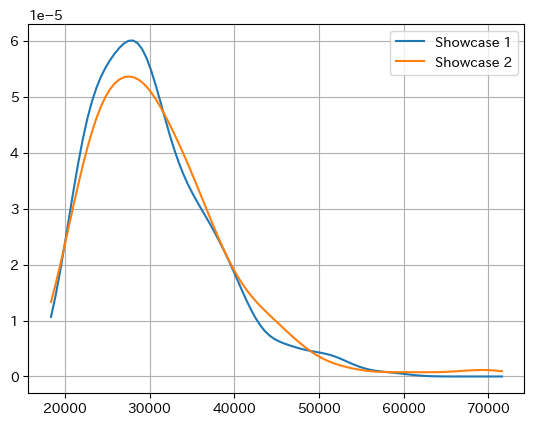

In [20]:
from scipy.stats import  gaussian_kde

kde1 = gaussian_kde(Showcase1)
kde2 = gaussian_kde(Showcase2)

xmin = min(min(Showcase1), min(Showcase2))
xmax = max(max(Showcase1), max(Showcase2))

x = np.linspace(xmin, xmax, 100)

pdf1 = kde1(x)
pdf2 = kde2(x)

mode_price1 = x[np.argmax(pdf1)]
mode_price2 = x[np.argmax(pdf2)]


print(f"{mode_price1:.0f}, {mode_price2:.0f}")

plt.plot(x, kde1(x), label='Showcase 1')
plt.plot(x, kde2(x), label='Showcase 2')
plt.legend()
plt.grid(True)